# Questão 4: O que a CNN aprendeu?

Aqui usamos a CNN treinada na Questão 3 para entender o que ela "enxerga":
- item a: os filtros da primeira camada convolucional e como eles mudam ao longo do treino;
- item b: os mapas de ativação de uma camada intermediária para algumas imagens de teste, e um teste de oclusão para ver quais regiões pesam na decisão;
- item c: exemplos que a rede acertou e que errou, com a probabilidade de cada previsão.

Este notebook usa os pesos salvos pela Questão 3 na pasta `checkpoints`. Por isso o notebook da Questão 3 precisa ser executado antes.

## Bibliotecas

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torchvision import datasets

# usa a placa de vídeo se tiver, senão usa o processador
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Rodando em:", device)

PASTA_DADOS = Path("../data/cifar10")
PASTA_MODELOS = Path("../checkpoints")
PASTA_FIGURAS = Path("../figures/q4")
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

CLASSES = ["avião", "automóvel", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

Rodando em: cuda


## Funções

Aqui ficam todas as funções que usamos no notebook. Cada uma tem uma explicação curta logo acima.

### fixar_semente
Fixa a "semente" dos sorteios para que os exemplos escolhidos ao acaso sejam sempre os mesmos.

In [2]:
def fixar_semente(semente=42):
    random.seed(semente)
    np.random.seed(semente)
    torch.manual_seed(semente)

### bloco_convolucional e CNN
A mesma rede da Questão 3. Precisamos escrever a arquitetura de novo aqui para conseguir carregar os pesos salvos: o arquivo guarda só os números (pesos), não o formato da rede.

In [3]:
def bloco_convolucional(entrada, saida, dropout):
    return nn.Sequential(
        nn.Conv2d(entrada, saida, kernel_size=3, padding=1),
        nn.BatchNorm2d(saida),
        nn.ReLU(),
        nn.Conv2d(saida, saida, kernel_size=3, padding=1),
        nn.BatchNorm2d(saida),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Dropout(dropout),
    )


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.bloco1 = bloco_convolucional(3, 64, dropout=0.1)
        self.bloco2 = bloco_convolucional(64, 128, dropout=0.2)
        self.bloco3 = bloco_convolucional(128, 256, dropout=0.3)
        self.saida = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 10))

    def forward(self, x):
        return self.saida(self.bloco3(self.bloco2(self.bloco1(x))))

### carregar_modelo
Lê um arquivo de pesos salvo pela Questão 3 e devolve a rede pronta para uso, junto com as informações salvas (época, média e desvio da normalização). Se o arquivo não existir, avisa que é preciso rodar a Questão 3 antes.

In [4]:
def carregar_modelo(nome_arquivo):
    caminho = PASTA_MODELOS / nome_arquivo
    if not caminho.exists():
        raise FileNotFoundError(f"Não achei {caminho}. Execute o notebook da Questão 3 antes deste.")
    salvo = torch.load(caminho, map_location=device, weights_only=True)
    modelo = CNN().to(device)
    modelo.load_state_dict(salvo["pesos"])
    modelo.eval()
    return modelo, salvo

### preparar_imagens
Transforma as imagens (valores de 0 a 255) no formato que a rede espera: canais na frente, pixels entre 0 e 1 e normalização com a mesma média e desvio usados no treino.

In [5]:
def preparar_imagens(imagens, media, desvio):
    x = torch.tensor(imagens, dtype=torch.float32, device=device).permute(0, 3, 1, 2) / 255.0
    return (x - media.to(device).view(1, 3, 1, 1)) / desvio.to(device).view(1, 3, 1, 1)

### prever
Devolve a classe prevista e a probabilidade de cada classe (softmax) para cada imagem.

In [6]:
def prever(modelo, X):
    modelo.eval()
    with torch.no_grad():
        probabilidades = torch.cat([torch.softmax(modelo(X[i:i + 1000]), dim=1) for i in range(0, len(X), 1000)])
    probabilidades = probabilidades.cpu().numpy()
    return probabilidades.argmax(axis=1), probabilidades

### filtros_para_imagem
Os filtros da primeira camada têm 3 x 3 pixels e 3 canais (vermelho, verde e azul), então dá para desenhá-los como pequenas imagens coloridas. Os pesos podem ser negativos, por isso esticamos os valores de cada filtro para ficarem entre 0 e 1 antes de desenhar.

In [7]:
def filtros_para_imagem(pesos):
    filtros = pesos.detach().cpu().permute(0, 2, 3, 1).numpy()  # (filtro, altura, largura, cor)
    minimo = filtros.min(axis=(1, 2, 3), keepdims=True)
    maximo = filtros.max(axis=(1, 2, 3), keepdims=True)
    return (filtros - minimo) / (maximo - minimo + 1e-8)

### grafico_filtros
Desenha os 64 filtros da primeira camada em uma grade de 8 x 8.

In [8]:
def grafico_filtros(pesos, titulo, eixos):
    filtros = filtros_para_imagem(pesos)
    for i, eixo in enumerate(eixos.flat):
        eixo.imshow(filtros[i], interpolation="nearest")
        eixo.axis("off")
    eixos.flat[0].figure.suptitle(titulo)

### capturar_ativacoes
Para ver os mapas de ativação, precisamos "espiar" a saída de uma camada que fica no meio da rede. Fazemos isso com um hook: uma função que o PyTorch chama automaticamente quando a imagem passa por aquela camada, e que guarda a saída dela.

In [9]:
def capturar_ativacoes(modelo, camada, X):
    guardado = {}

    def hook(modulo, entrada, saida):
        guardado["ativacoes"] = saida.detach()

    gancho = camada.register_forward_hook(hook)
    with torch.no_grad():
        modelo(X)
    gancho.remove()
    return guardado["ativacoes"]

### mapa_medio_ativacao
Resume os mapas de uma camada em um só: tira a média de todos os mapas e amplia o resultado para 32 x 32, o tamanho da imagem, para poder desenhar por cima dela.

In [10]:
def mapa_medio_ativacao(ativacoes):
    mapa = ativacoes.mean(dim=0, keepdim=True).unsqueeze(0)
    return F.interpolate(mapa, size=(32, 32), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()

### mapa_oclusao
Um mapa de ativação mostra onde a camada responde, mas responder forte não é o mesmo que ser importante para a decisão. Para medir a importância de cada região fazemos um teste direto: tapamos um quadrado de 6 x 6 pixels da imagem com a cor média e vemos quanto a vantagem da classe certa cai. Repetimos isso deslizando o quadrado pela imagem inteira (de 2 em 2 pixels, 196 posições).

O resultado é um mapa de 32 x 32: cada pixel guarda a queda média das vezes em que ele foi tapado. Valores altos indicam regiões de que a rede precisa para acertar. Valores negativos indicam regiões que atrapalham (tapar aumenta a vantagem da classe certa).

A "vantagem" é a margem: a nota que a rede dá para a classe certa (a saída antes do softmax) menos a maior nota entre as outras nove classes. Margem positiva quer dizer que a rede acerta; se ela ficar negativa, a rede passou a errar. Usamos a margem, e não a probabilidade, porque nestas imagens a rede tem quase 100% de certeza e a probabilidade quase não se mexe quando tapamos um pedaço pequeno.

A função devolve o mapa e a margem da imagem inteira, sem nada tapado.

In [11]:
def mapa_oclusao(modelo, x, classe, tamanho=6, passo=2):
    posicoes = [(linha, coluna) for linha in range(0, 32 - tamanho + 1, passo) for coluna in range(0, 32 - tamanho + 1, passo)]
    tapadas = x.unsqueeze(0).repeat(len(posicoes), 1, 1, 1)
    for k, (linha, coluna) in enumerate(posicoes):
        tapadas[k, :, linha:linha + tamanho, coluna:coluna + tamanho] = 0  # depois da normalização, 0 é a cor média
    modelo.eval()
    with torch.no_grad():
        saidas = modelo(torch.cat([x.unsqueeze(0), tapadas])).float()
    outras = saidas.clone()
    outras[:, classe] = float("-inf")
    margem = (saidas[:, classe] - outras.max(dim=1).values).cpu().numpy()
    queda = margem[0] - margem[1:]

    soma = np.zeros((32, 32))
    vezes = np.zeros((32, 32))
    for k, (linha, coluna) in enumerate(posicoes):
        soma[linha:linha + tamanho, coluna:coluna + tamanho] += queda[k]
        vezes[linha:linha + tamanho, coluna:coluna + tamanho] += 1
    return soma / vezes, float(margem[0])

### mostrar_ativacoes
Para uma imagem, mostra:
- a imagem original;
- o mapa médio de ativação (a média dos 128 mapas) por cima da imagem: as regiões em amarelo são as que mais ativaram a camada;
- os 16 mapas (filtros) que tiveram a maior ativação média nessa imagem.

Nos mapas, cores claras indicam onde o filtro "encontrou" o padrão que ele procura.

In [12]:
def mostrar_ativacoes(imagem_original, ativacoes, titulo, arquivo=None):
    mapa_medio = mapa_medio_ativacao(ativacoes)
    mais_ativos = ativacoes.mean(dim=(1, 2)).argsort(descending=True)[:16].cpu().numpy()

    fig = plt.figure(figsize=(13, 4.3))
    grade = fig.add_gridspec(4, 8)
    eixo_original = fig.add_subplot(grade[0:4, 0:2])
    eixo_original.imshow(imagem_original)
    eixo_original.set_title("original")
    eixo_original.axis("off")
    eixo_medio = fig.add_subplot(grade[0:4, 2:4])
    eixo_medio.imshow(imagem_original)
    eixo_medio.imshow(mapa_medio, cmap="inferno", alpha=0.6)
    eixo_medio.set_title("ativação média")
    eixo_medio.axis("off")
    for k, filtro in enumerate(mais_ativos):
        eixo = fig.add_subplot(grade[k // 4, 4 + k % 4])
        eixo.imshow(ativacoes[filtro].cpu().numpy(), cmap="viridis")
        eixo.set_title(f"filtro {filtro}", fontsize=7)
        eixo.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

### grade_de_previsoes
Mostra várias imagens com a classe real, a classe prevista e a probabilidade que a rede deu para a classe prevista. Título verde quando a rede acertou e vermelho quando errou. Nos erros mostramos também a probabilidade que a rede deu para a classe certa.

In [13]:
def grade_de_previsoes(indices, imagens, reais, previstos, probabilidades, titulo, arquivo=None):
    fig, eixos = plt.subplots(2, 5, figsize=(13, 6.6), gridspec_kw={"hspace": 0.3})
    for eixo, i in zip(eixos.flat, indices):
        eixo.imshow(imagens[i])
        eixo.axis("off")
        acertou = reais[i] == previstos[i]
        texto = f"real: {CLASSES[reais[i]]}\nprevista: {CLASSES[previstos[i]]}\nprob.: {probabilidades[i, previstos[i]]:.1%}"
        if not acertou:
            texto += f"\nprob. da certa: {probabilidades[i, reais[i]]:.1%}"
        eixo.set_title(texto, fontsize=9, color="green" if acertou else "red")
    fig.suptitle(titulo, y=1.0)
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

---
# Preparando

## Carregando a CNN treinada na Questão 3
Carregamos os pesos da rede em quatro momentos: antes do treino (época 0, pesos ainda sorteados), depois da 1ª época, depois da 5ª época e no final.

In [14]:
cnn_epoca_0, info_0 = carregar_modelo("cnn_epoca_00.pt")
cnn_epoca_1, info_1 = carregar_modelo("cnn_epoca_01.pt")
cnn_epoca_5, info_5 = carregar_modelo("cnn_epoca_05.pt")
cnn, info_final = carregar_modelo("cnn_final.pt")
media, desvio = info_final["media"], info_final["desvio"]
etapas = {"época 0": cnn_epoca_0, "época 1": cnn_epoca_1, "época 5": cnn_epoca_5, "final": cnn}
print("Épocas carregadas:", info_0["epoca"], info_1["epoca"], info_5["epoca"], info_final["epoca"])

Épocas carregadas: 0 1 5 38


## Carregando as imagens de teste

In [15]:
teste = datasets.CIFAR10(PASTA_DADOS, train=False, download=True)
imagens_teste = teste.data
classes_teste = np.array(teste.targets)
X_teste = preparar_imagens(imagens_teste, media, desvio)
print("Imagens de teste:", imagens_teste.shape)

Imagens de teste: (10000, 32, 32, 3)


## Acurácia da rede em cada momento do treino

In [16]:
previstos_por_epoca = {}
for nome, modelo in etapas.items():
    previstos_por_epoca[nome], _ = prever(modelo, X_teste)
pd.Series({nome: (p == classes_teste).mean() for nome, p in previstos_por_epoca.items()}, name="acurácia no teste").round(4)

época 0    0.1000
época 1    0.5498
época 5    0.6906
final      0.9193
Name: acurácia no teste, dtype: float64

Antes do treino (época 0) a rede acerta 10,0%, o mesmo que um chute entre 10 classes. A acurácia sobe para 55,0% depois da 1ª época, 69,1% depois da 5ª e chega a 91,9% no final. O modelo "final" é o da melhor época da Questão 3 (época 38). Esses quatro modelos vão mostrar como os filtros e as ativações mudam enquanto a rede aprende.

---
# Item a: filtros da primeira camada convolucional

A primeira camada tem 64 filtros. Cada filtro tem 3 x 3 pixels e 3 cores. Quando o filtro passa pela imagem, ele responde forte nos lugares em que a imagem se parece com ele.

## Filtros no final do treino

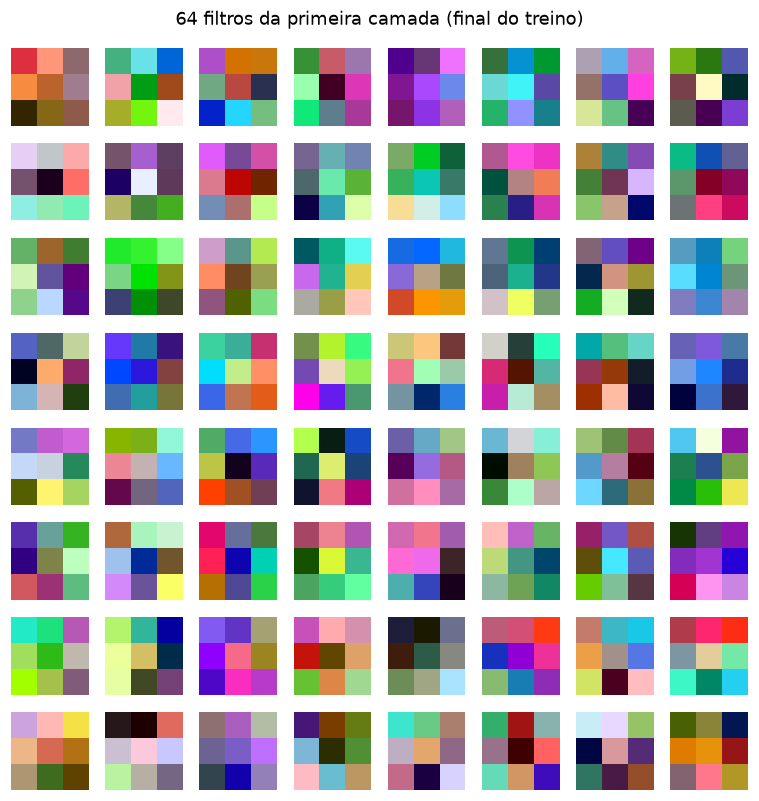

In [17]:
fig, eixos = plt.subplots(8, 8, figsize=(7, 7.4))
grafico_filtros(cnn.bloco1[0].weight, "64 filtros da primeira camada (final do treino)", eixos)
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "4a_filtros_final.png", bbox_inches="tight")
plt.show()

O que observar:
- Cada quadradinho é um filtro de 3x3 pixels. As cores mostram quanto o filtro "gosta" de vermelho, verde e azul em cada posição.
- Com só 3x3 pixels não dá para ver desenhos grandes. Mesmo assim, vários filtros têm um lado visivelmente mais claro que o outro. Dois exemplos fáceis de achar na figura: o da 7ª linha, 2ª coluna, com a coluna da esquerda amarelo-esverdeada e a da direita azul-escura, e o da 8ª linha, 7ª coluna, com a linha de cima bem clara e as duas de baixo escuras. Esse tipo de filtro responde a bordas, ou seja, lugares onde a imagem muda de claro para escuro.
- Outros filtros juntam cores opostas dentro do mesmo quadradinho. Um exemplo é o da 3ª linha, 5ª coluna, azul em cima e laranja embaixo. Eles respondem a mudanças de cor, e não de brilho: por exemplo, um céu azul em cima de um chão alaranjado.
- Alguns filtros são quase de uma cor só, como o da 3ª linha, 2ª coluna, todo verde. Eles respondem à cor da região, e não à forma.
- Dois cuidados ao ler esta figura. Primeiro, para desenhar, esticamos os valores de cada filtro até ocuparem o intervalo inteiro de 0 a 1, o que exagera os contrastes: um filtro com pesos quase iguais aparece tão colorido quanto um filtro com pesos bem diferentes. Segundo, um filtro 3x3 sorteado ao acaso também mostra "lados claros" e "cores opostas". Então esta figura sozinha não prova que esses desenhos foram aprendidos. É isso que verificamos a seguir, comparando com os filtros de antes do treino.

## Filtros ao longo do treino
Mostramos os mesmos 16 filtros antes do treino (época 0), depois da 1ª época, da 5ª época e no final.

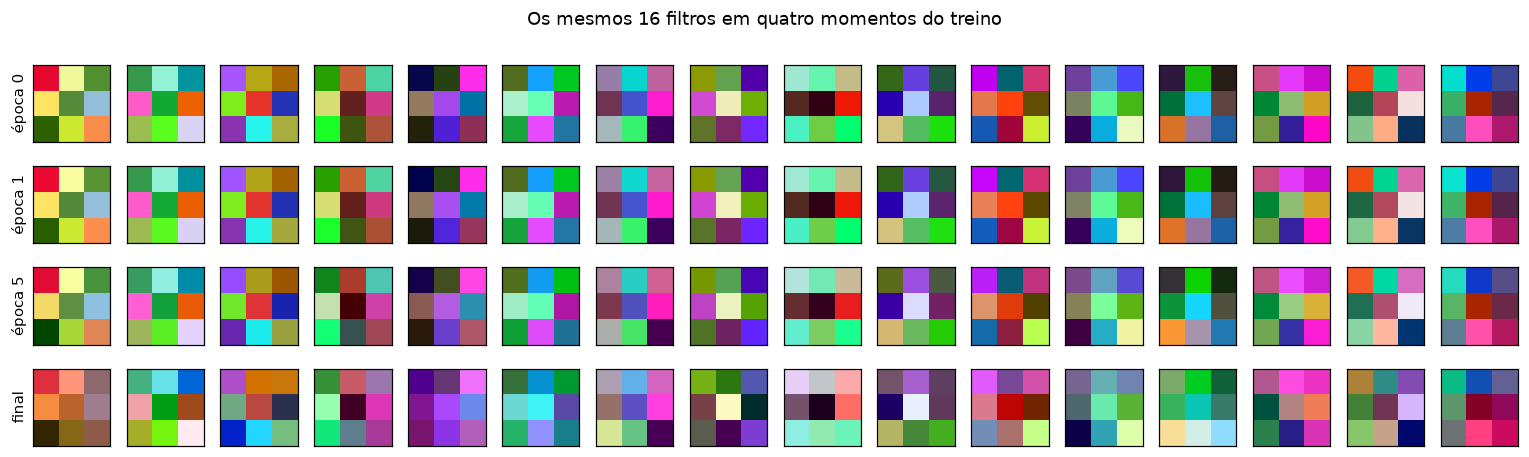

In [18]:
fig, eixos = plt.subplots(4, 16, figsize=(14, 4.3))
for linha, (nome, modelo) in enumerate(etapas.items()):
    filtros = filtros_para_imagem(modelo.bloco1[0].weight)
    for coluna in range(16):
        eixos[linha, coluna].imshow(filtros[coluna], interpolation="nearest")
        eixos[linha, coluna].set_xticks([])
        eixos[linha, coluna].set_yticks([])
    eixos[linha, 0].set_ylabel(nome)
plt.suptitle("Os mesmos 16 filtros em quatro momentos do treino")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "4a_filtros_evolucao.png", bbox_inches="tight")
plt.show()

O que observar:
- As linhas da época 0 (pesos sorteados) e da época 1 são praticamente idênticas, e a da época 5 muda muito pouco (só alguns tons). Mesmo assim a rede já acerta 69% na época 5. Ou seja, no começo do treino quem aprende são as camadas seguintes; a primeira camada continua quase igual ao sorteio.
- Da época 5 até o final os filtros mudam de forma visível. O 1º perde o amarelo e o verde e fica em tons de vermelho e marrom, e o 5º fica quase todo roxo. Mas muitos continuam reconhecíveis: o 2º, o 3º, o 7º e o 14º mantêm o mesmo desenho geral, só com as cores ajustadas.
- Faz sentido com o OneCycle: a taxa de aprendizado é pequena nas primeiras épocas e só chega ao máximo por volta da época 12. É nessa fase que os pesos mais mudam.
- A conclusão importante é que o treino não criou os filtros do zero. Ele partiu dos filtros sorteados e foi ajustando cada um.

## Quanto os filtros mudaram
Para não depender só do olho, medimos a mudança entre cada par de momentos, filtro por filtro, de duas formas:
- distância: o tamanho da diferença entre os pesos (quanto maior, mais o filtro mudou);
- semelhança de cosseno: compara só o "desenho" do filtro, ignorando a intensidade. Vale 1 quando o desenho é o mesmo, 0 quando não tem nada a ver e -1 quando é o oposto. Ela é importante aqui porque depois da convolução vem um BatchNorm, que desfaz qualquer mudança de escala: multiplicar um filtro inteiro por 2 muda a distância, mas não muda o que a rede calcula.

A tabela mostra a média dos 64 filtros.

In [19]:
pesos_etapas = {nome: modelo.bloco1[0].weight.detach().flatten(1) for nome, modelo in etapas.items()}
pares = [("época 0", "época 1"), ("época 1", "época 5"), ("época 5", "final"), ("época 0", "final")]

linhas_mudanca = {}
for antes, depois in pares:
    a, b = pesos_etapas[antes], pesos_etapas[depois]
    cosseno = F.cosine_similarity(a, b, dim=1)
    linhas_mudanca[f"{antes} → {depois}"] = {
        "distância média": (b - a).norm(dim=1).mean().item(),
        "semelhança de cosseno média": cosseno.mean().item(),
        "menor semelhança": cosseno.min().item(),
        "maior semelhança": cosseno.max().item(),
    }
tabela_mudanca = pd.DataFrame(linhas_mudanca).T
tabela_mudanca.round(3)

,distância média,semelhança de cosseno média,menor semelhança,maior semelhança
época 0 → época 1,0.024,0.999,0.994,1.000
época 1 → época 5,0.101,0.980,0.877,0.999
época 5 → final,0.593,0.894,0.692,0.955
época 0 → final,0.638,0.851,0.674,0.938


In [20]:
pd.Series({nome: pesos.norm(dim=1).mean().item() for nome, pesos in pesos_etapas.items()},
          name="tamanho médio dos filtros (norma)").round(3)

época 0    0.572
época 1    0.571
época 5    0.579
final      1.053
Name: tamanho médio dos filtros (norma), dtype: float64

A tabela confirma e mede o que vimos nas imagens:
- Da época 0 para a época 1 os filtros quase não mudam (semelhança de 0,999). Da época 1 para a 5 mudam pouco (0,980). A maior parte da mudança acontece depois da época 5: a distância desse trecho (0,593) é quase toda a distância entre o início e o final (0,638).
- Mesmo no final, os filtros continuam parecidos com os sorteados: a semelhança de cosseno média entre a época 0 e o final é 0,851, e o filtro que mais mudou ainda tem 0,674. Para comparar, dois filtros sorteados sem relação um com o outro teriam semelhança perto de 0. Então todos os 64 filtros finais são versões ajustadas dos filtros iniciais.
- Parte da distância é só mudança de tamanho: a norma média dos filtros quase dobrou, de 0,57 para 1,05. Como existe um BatchNorm logo depois, esse aumento de escala não muda o que a rede calcula. Por isso a semelhança de cosseno é a medida mais confiável aqui.

O que isso quer dizer: com filtros de só 3x3 pixels, um conjunto de 64 filtros sorteados já cobre bem as bordas e os contrastes de cor possíveis, e a rede precisa apenas ajustá-los. Isso indica que boa parte do que a CNN aprendeu está nas camadas seguintes, que combinam essas respostas simples. Um ajuste pequeno na direção de um filtro ainda pode ser importante, então não dá para dizer que a primeira camada "não aprendeu nada"; dá para dizer que ela mudou pouco.

## O que cada filtro destaca em uma imagem
Para entender melhor os filtros, aplicamos a primeira camada em uma imagem e mostramos a resposta de 16 filtros.

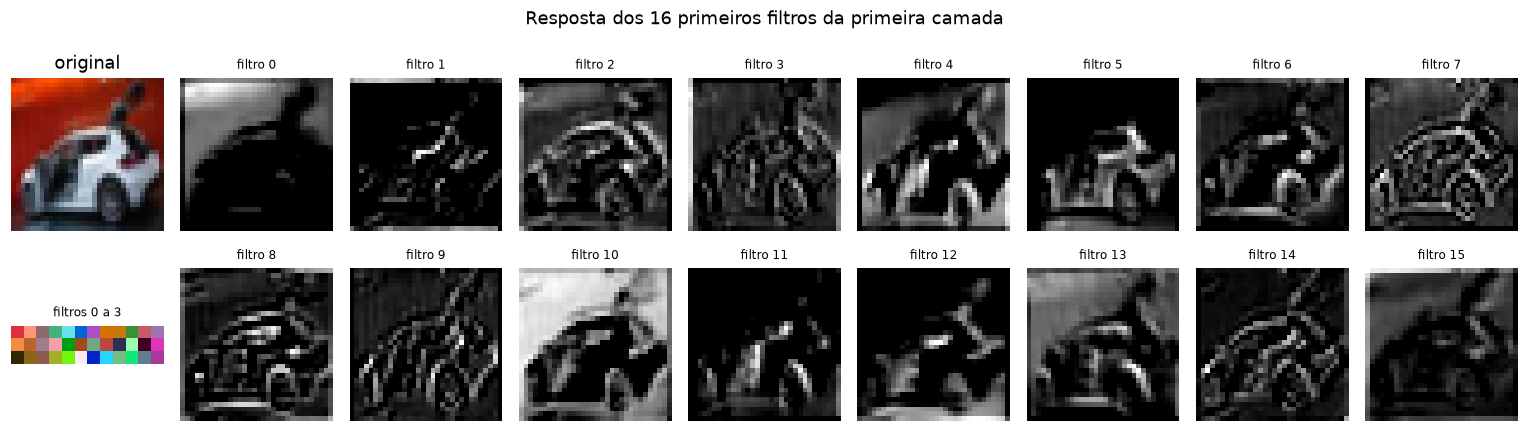

In [21]:
indice_exemplo = int(np.where(classes_teste == 1)[0][0])  # primeiro automóvel do teste
respostas = capturar_ativacoes(cnn, cnn.bloco1[2], X_teste[indice_exemplo:indice_exemplo + 1])[0]

fig, eixos = plt.subplots(2, 9, figsize=(14, 4.2))
eixos[0, 0].imshow(imagens_teste[indice_exemplo])
eixos[0, 0].set_title("original")
filtros_final = filtros_para_imagem(cnn.bloco1[0].weight)
for k in range(16):
    eixo = eixos[k // 8, 1 + k % 8]
    eixo.imshow(respostas[k].cpu().numpy(), cmap="gray")
    eixo.set_title(f"filtro {k}", fontsize=8)
eixos[1, 0].imshow(np.concatenate([filtros_final[k] for k in range(4)], axis=1), interpolation="nearest")
eixos[1, 0].set_title("filtros 0 a 3", fontsize=8)
for eixo in eixos.flat:
    eixo.axis("off")
plt.suptitle("Resposta dos 16 primeiros filtros da primeira camada")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "4a_respostas_filtros.png", bbox_inches="tight")
plt.show()

O que observar (claro = o filtro respondeu forte, escuro = não respondeu):
- Vários filtros (por exemplo, 2, 7, 8, 9 e 14) desenham o contorno do carro: rodas, janelas e a borda da lataria. Eles respondem a bordas.
- Outros respondem a regiões inteiras: o filtro 10 acende em todo o fundo e deixa o carro escuro, e os filtros 5 e 12 fazem o contrário, acendendo nas partes brancas da lataria. Eles respondem a cor e brilho.
- O filtro 0 quase não responde: só acende em uma faixa no alto, onde o fundo é um laranja mais claro.
- Juntos, esses 64 mapas são a "matéria-prima" que as próximas camadas usam para reconhecer o objeto.

---
# Item b: mapas de ativação de uma camada intermediária

Usamos a saída do bloco 2 da CNN (depois da segunda convolução e da ReLU). Nesse ponto a imagem já foi reduzida para 16 x 16 e existem 128 mapas, um para cada filtro. Essa camada fica no meio da rede: ela já combina bordas e cores em padrões mais complexos, mas ainda guarda onde as coisas estão na imagem.

## Escolhendo as imagens
Pegamos a primeira imagem de teste que a rede acertou de seis classes diferentes.

In [22]:
previstos, probabilidades = prever(cnn, X_teste)
classes_escolhidas = ["avião", "automóvel", "pássaro", "gato", "cavalo", "navio"]
indices_ativacao = []
for nome in classes_escolhidas:
    c = CLASSES.index(nome)
    indices_ativacao.append(int(np.where((classes_teste == c) & (previstos == c))[0][0]))
print("Índices escolhidos:", indices_ativacao)

camada_intermediaria = cnn.bloco2[5]  # ReLU depois da segunda convolução do bloco 2
ativacoes = capturar_ativacoes(cnn, camada_intermediaria, X_teste[indices_ativacao])
print("Formato das ativações:", tuple(ativacoes.shape))

Índices escolhidos: [3, 6, 25, 0, 13, 1]
Formato das ativações: (6, 128, 16, 16)


## Imagem 1: avião

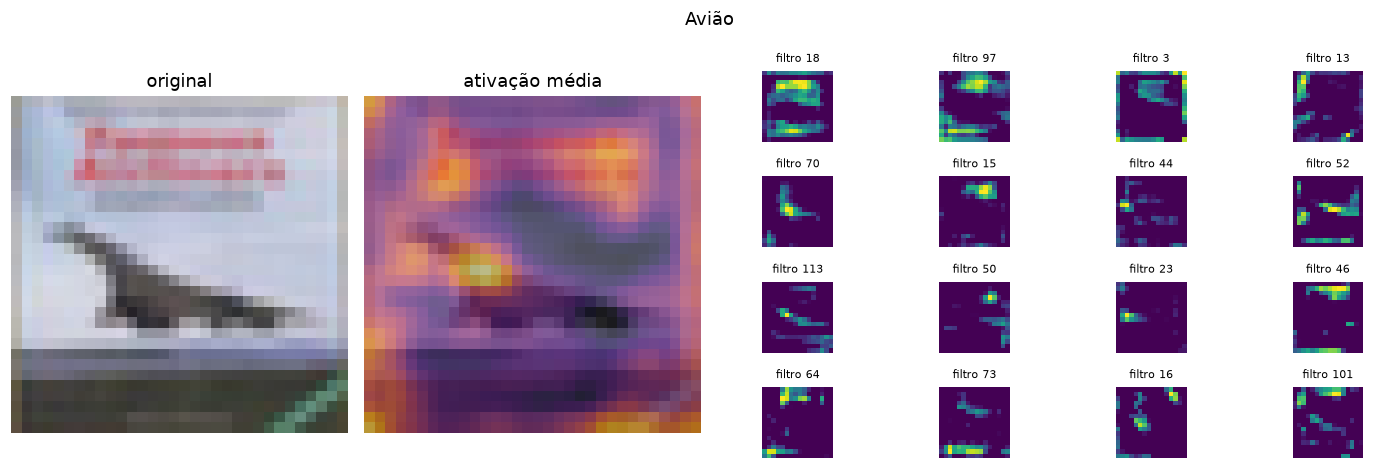

In [23]:
mostrar_ativacoes(imagens_teste[indices_ativacao[0]], ativacoes[0], "Avião", arquivo="4b_ativacoes_aviao.png")

O que observar:
- A ativação média é mais forte na placa com texto, no alto da imagem, e na ponta esquerda do avião. O corpo escuro do avião quase não ativa.
- Nos mapas individuais, os filtros 18 e 97 acendem na placa com texto, e os filtros 70, 113 e 23 acendem em pontos e traços ao longo da linha diagonal do avião.
- O céu claro e liso quase não ativa. Esta camada responde a qualquer contorno marcado, e não só ao avião.

## Imagem 2: automóvel

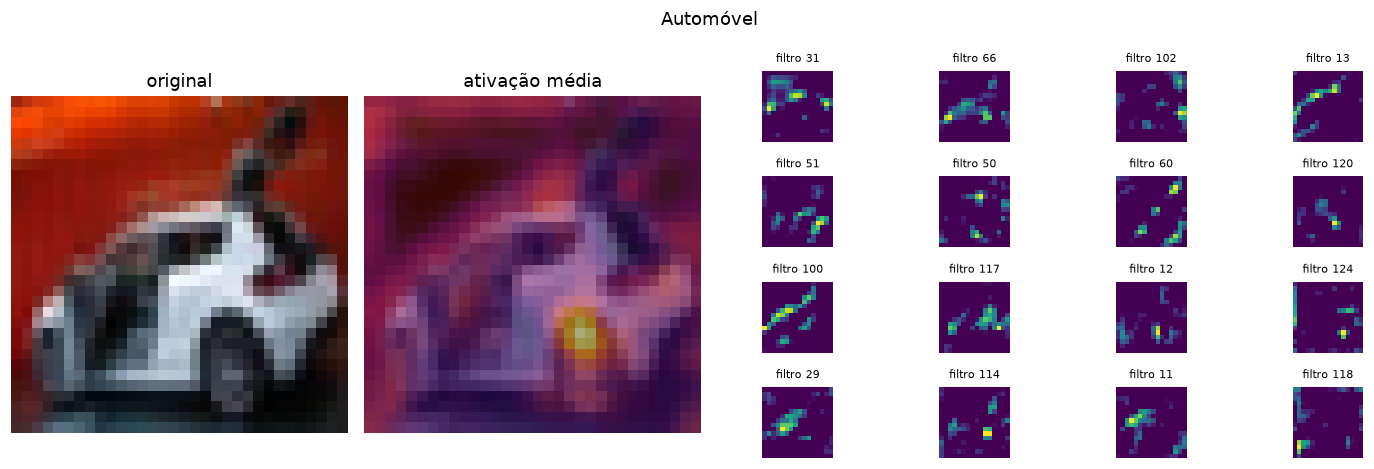

In [24]:
mostrar_ativacoes(imagens_teste[indices_ativacao[1]], ativacoes[1], "Automóvel", arquivo="4b_ativacoes_automovel.png")

O que observar:
- A ativação média tem um ponto forte na roda da frente (região amarela). No resto do carro ela é fraca.
- Vários mapas (filtros 13, 100, 29 e 66) acendem em linhas diagonais, que acompanham o contorno do teto, da janela e do capô.
- O fundo vermelho, mesmo sendo bem chamativo, ativa pouco nesta camada. Isso ainda não diz se o fundo pesa ou não na decisão; esse teste aparece mais abaixo, na seção de oclusão.

## Imagem 3: pássaro

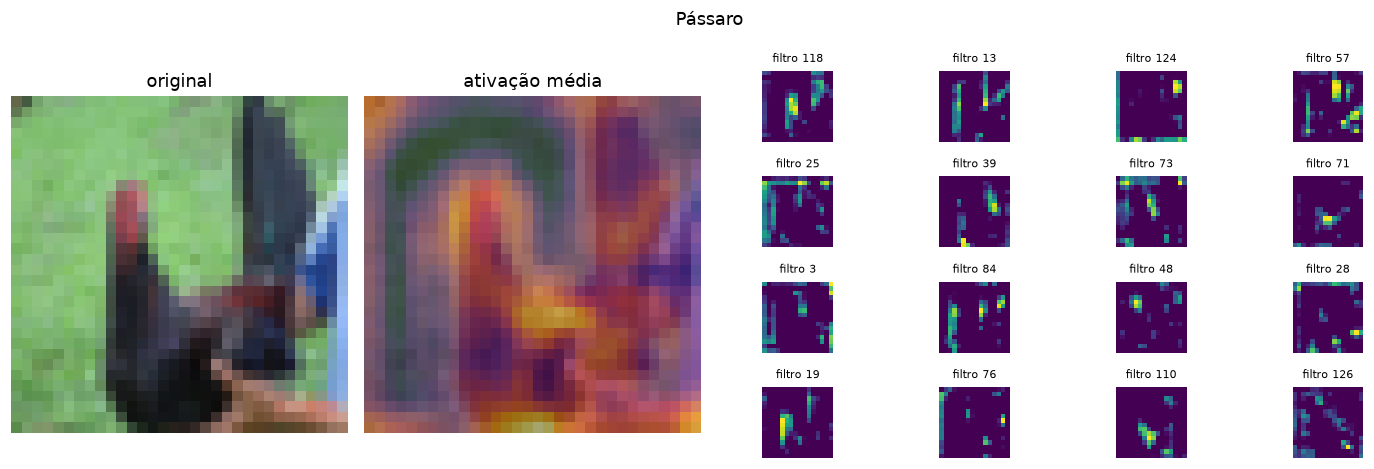

In [25]:
mostrar_ativacoes(imagens_teste[indices_ativacao[2]], ativacoes[2], "Pássaro", arquivo="4b_ativacoes_passaro.png")

O que observar:
- As regiões mais ativas são a cabeça vermelha e o pescoço do pássaro e a parte de baixo do corpo, perto das patas.
- Muitos mapas (filtros 118, 57, 19 e 84) respondem a traços verticais, que acompanham o pescoço e a cauda em pé.
- A grama verde do fundo fica escura, ou seja, quase não ativa.

## Imagem 4: gato

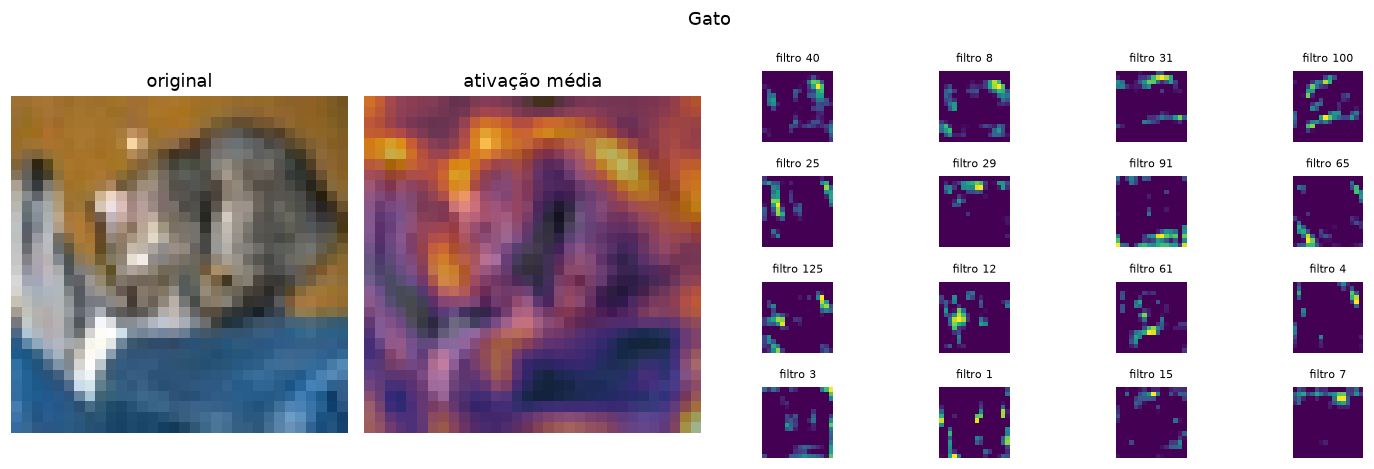

In [26]:
mostrar_ativacoes(imagens_teste[indices_ativacao[3]], ativacoes[3], "Gato", arquivo="4b_ativacoes_gato.png")

O que observar:
- Essa imagem é difícil: o gato tem uma pelagem com manchas que se mistura com o fundo.
- A ativação média é forte na linha do topo, onde o fundo laranja encontra a cabeça e as costas do gato. O tecido azul de baixo quase não ativa.
- Os mapas individuais são espalhados e com pontos isolados. Alguns acendem na linha do topo (filtros 31, 29 e 7) e outros perto do rosto (filtros 12 e 61), mas não há uma forma tão clara como no carro ou no cavalo.

## Imagem 5: cavalo

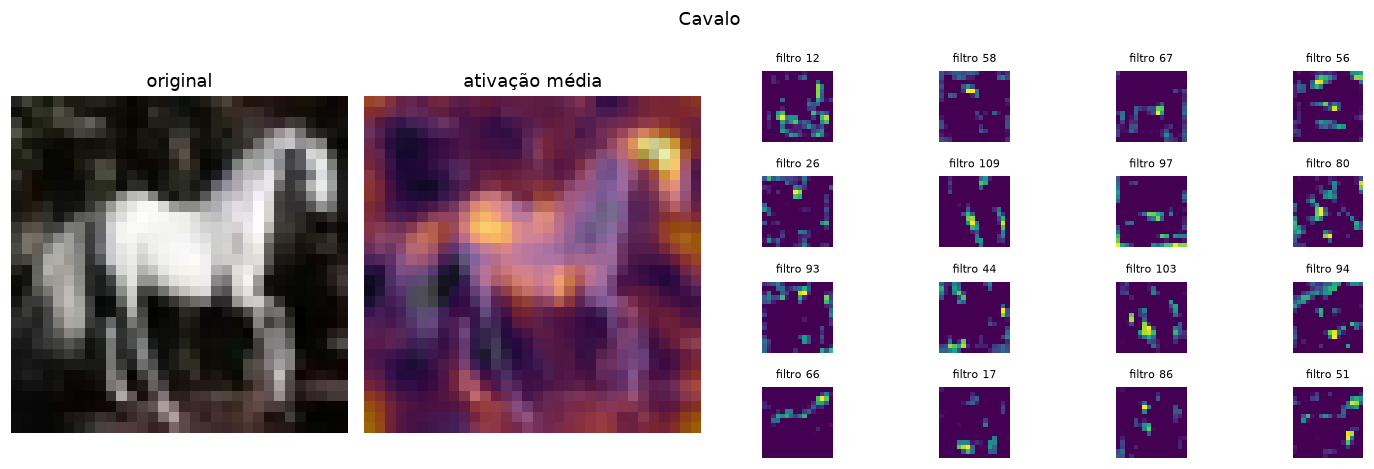

In [27]:
mostrar_ativacoes(imagens_teste[indices_ativacao[4]], ativacoes[4], "Cavalo", arquivo="4b_ativacoes_cavalo.png")

O que observar:
- A ativação média tem dois pontos fortes: a cabeça do cavalo, no alto à direita, e a parte da frente do dorso. O fundo escuro quase não ativa, e as pernas aparecem fracas.
- Alguns mapas (filtros 66 e 94) seguem a linha das costas e do pescoço. Outros (filtros 109 e 103) acendem em pontos na região das pernas.
- O contraste entre o cavalo claro e o fundo escuro facilita: os contornos do animal ficam bem marcados.

## Imagem 6: navio

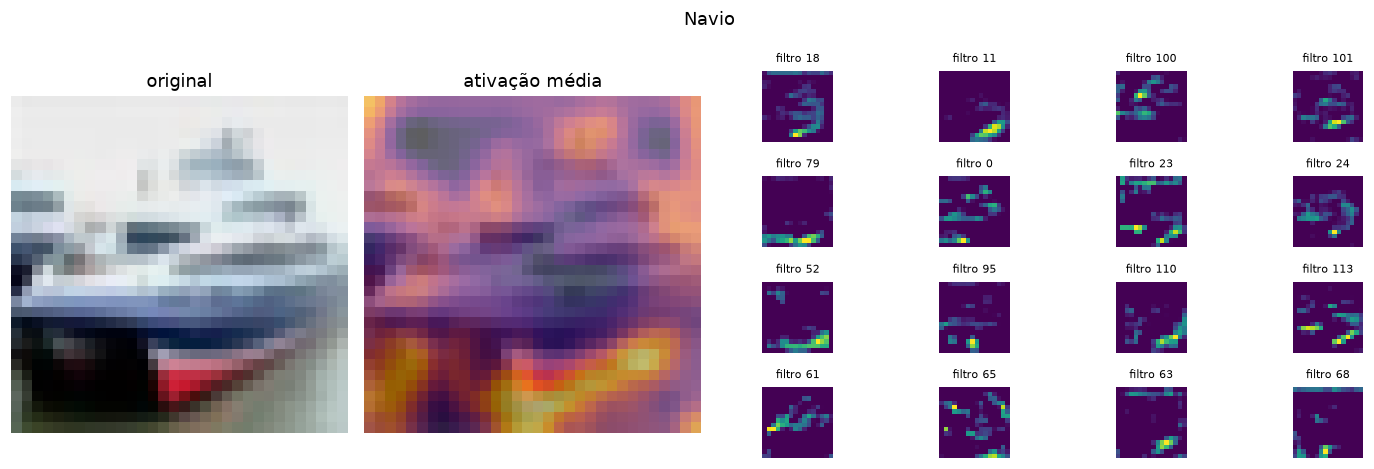

In [28]:
mostrar_ativacoes(imagens_teste[indices_ativacao[5]], ativacoes[5], "Navio", arquivo="4b_ativacoes_navio.png")

O que observar:
- A ativação média é mais forte na parte de baixo, no casco vermelho e na linha da água.
- Vários mapas (filtros 11, 52, 110 e 63) acendem em uma linha diagonal na parte de baixo, à direita: é a borda inclinada do casco. O filtro 79 acende em uma faixa horizontal na base da imagem.
- A parte branca de cima e o céu claro ativam menos.

## Os mapas de ativação ao longo do treino
Para as mesmas seis imagens, mostramos a ativação média da mesma camada nos quatro momentos do treino.

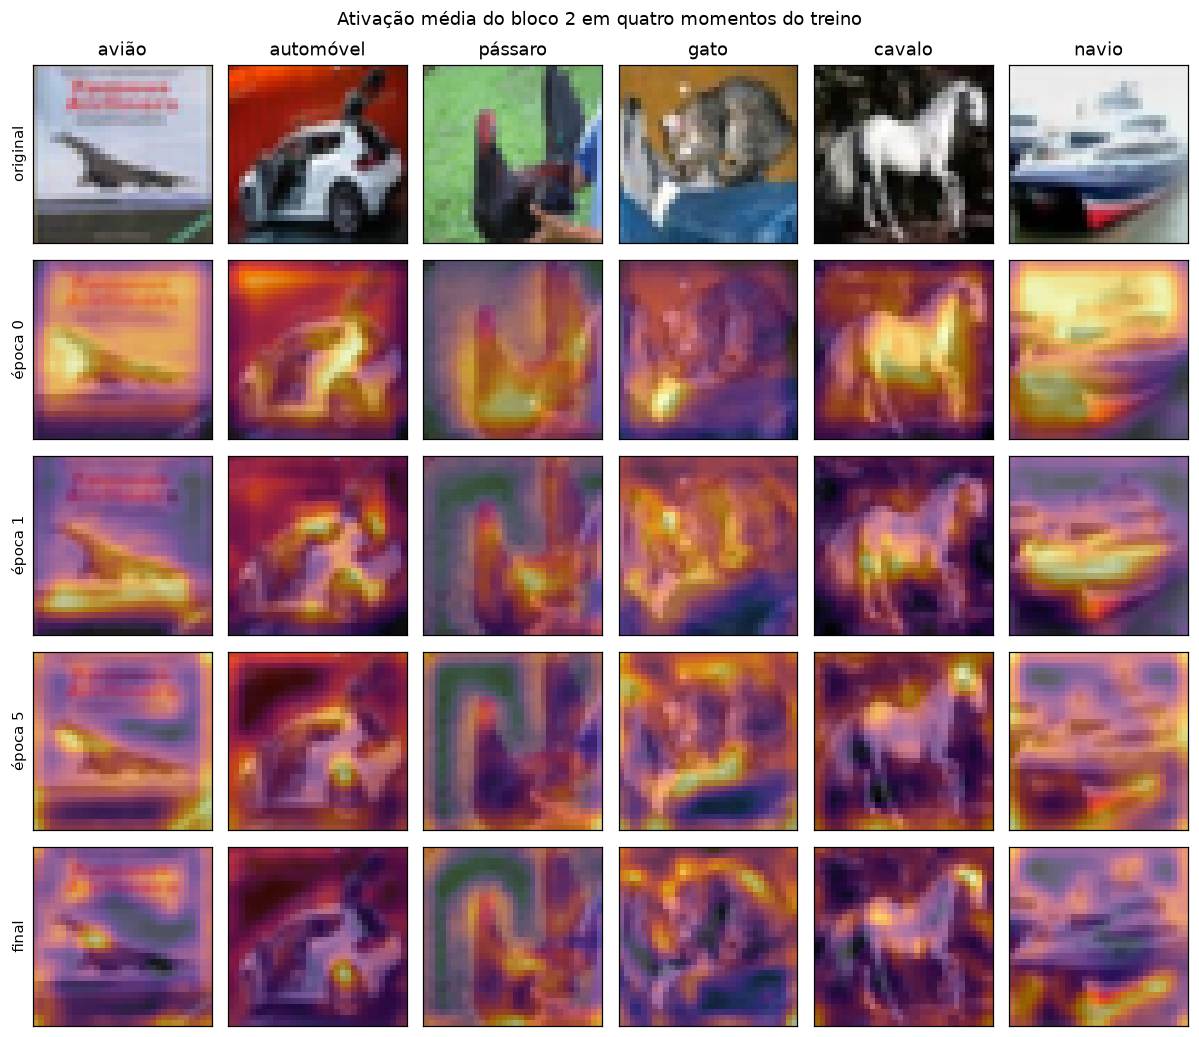

In [29]:
fig, eixos = plt.subplots(len(etapas) + 1, 6, figsize=(11, 9.6))
for coluna, indice in enumerate(indices_ativacao):
    eixos[0, coluna].imshow(imagens_teste[indice])
    eixos[0, coluna].set_title(classes_escolhidas[coluna])
for linha, (nome, modelo) in enumerate(etapas.items(), start=1):
    ativacoes_etapa = capturar_ativacoes(modelo, modelo.bloco2[5], X_teste[indices_ativacao])
    for coluna, indice in enumerate(indices_ativacao):
        eixos[linha, coluna].imshow(imagens_teste[indice])
        eixos[linha, coluna].imshow(mapa_medio_ativacao(ativacoes_etapa[coluna]), cmap="inferno", alpha=0.6)
    eixos[linha, 0].set_ylabel(nome)
eixos[0, 0].set_ylabel("original")
for eixo in eixos.flat:
    eixo.set_xticks([])
    eixo.set_yticks([])
plt.suptitle("Ativação média do bloco 2 em quatro momentos do treino")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "4b_ativacoes_evolucao.png", bbox_inches="tight")
plt.show()

O que observar:
- A linha da época 0 é a mais surpreendente. A rede ainda tem os pesos sorteados e acerta só 10%, mas o mapa médio já desenha a silhueta dos objetos: o cavalo aparece inteiro aceso, e o avião e o carro também se destacam. Uma rede sem treino responde principalmente a brilho e contraste, e nessas fotos o objeto é a parte mais clara ou mais contrastada (o cavalo branco no fundo escuro, o carro branco no fundo vermelho).
- Isso é um aviso para a leitura dos mapas: ativação forte em cima do objeto não prova que a rede "sabe" o que é o objeto. Uma rede que não aprendeu nada mostra a mesma coisa.
- Com o treino os mapas ficam mais seletivos. Na época 1 a ativação ainda cobre regiões inteiras. No final ela se concentra em poucos pontos (a roda do carro, a cabeça do cavalo, o casco do navio), e regiões claras e lisas que acendiam no início se apagam (o corpo do cavalo, o céu em cima do navio).
- Ou seja, o que o treino mudou nesta camada foi o tipo de coisa a que ela responde: de "onde a imagem é clara" para "onde existem certos contornos e partes".

## Quais regiões realmente pesam na decisão
Os mapas acima mostram onde a camada intermediária responde. Isso ainda não diz quais regiões contribuíram para a resposta final da rede. Para medir isso usamos o teste de oclusão (função `mapa_oclusao`): tapamos um pedaço da imagem de cada vez e medimos quanto a margem da classe certa cai.

Em cada coluna: a imagem, a ativação média do bloco 2 e o mapa de oclusão. No mapa de oclusão, vermelho marca as regiões que fazem a margem cair quando são tapadas (a rede precisa delas) e azul marca as regiões que fazem a margem subir (elas atrapalhavam). Embaixo de cada mapa está a margem da imagem inteira e a maior queda do mapa.

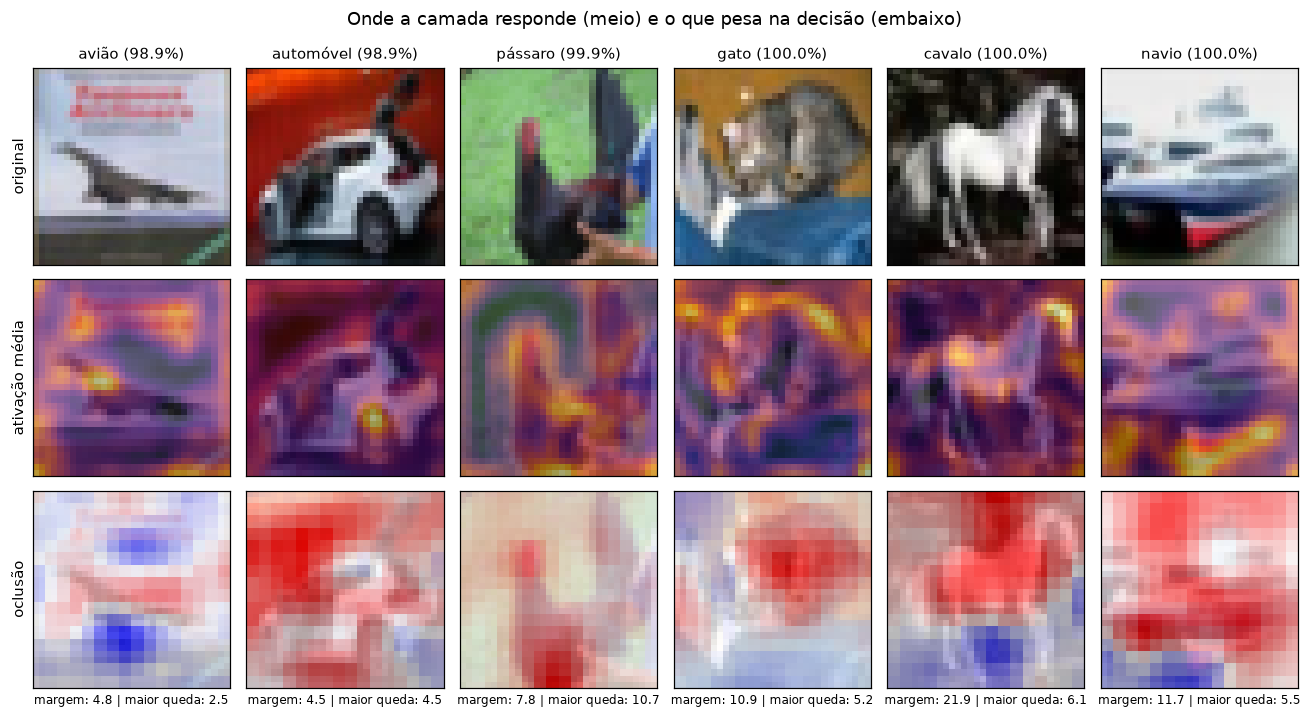

In [30]:
mapas_ativacao = [mapa_medio_ativacao(ativacoes[k]) for k in range(len(indices_ativacao))]
resultados_oclusao = [mapa_oclusao(cnn, X_teste[indice], int(classes_teste[indice])) for indice in indices_ativacao]
mapas_oclusao = [mapa for mapa, _ in resultados_oclusao]
margens = [margem for _, margem in resultados_oclusao]

fig, eixos = plt.subplots(3, 6, figsize=(12, 6.6))
for coluna, indice in enumerate(indices_ativacao):
    eixos[0, coluna].imshow(imagens_teste[indice])
    eixos[0, coluna].set_title(f"{classes_escolhidas[coluna]} ({probabilidades[indice, classes_teste[indice]]:.1%})", fontsize=10)
    eixos[1, coluna].imshow(imagens_teste[indice])
    eixos[1, coluna].imshow(mapas_ativacao[coluna], cmap="inferno", alpha=0.6)
    limite = np.abs(mapas_oclusao[coluna]).max()
    eixos[2, coluna].imshow(imagens_teste[indice])
    eixos[2, coluna].imshow(mapas_oclusao[coluna], cmap="bwr", vmin=-limite, vmax=limite, alpha=0.7)
    eixos[2, coluna].set_xlabel(f"margem: {margens[coluna]:.1f} | maior queda: {mapas_oclusao[coluna].max():.1f}", fontsize=8)
for eixo, nome in zip(eixos[:, 0], ["original", "ativação média", "oclusão"]):
    eixo.set_ylabel(nome)
for eixo in eixos.flat:
    eixo.set_xticks([])
    eixo.set_yticks([])
plt.suptitle("Onde a camada responde (meio) e o que pesa na decisão (embaixo)")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "4b_oclusao.png", bbox_inches="tight")
plt.show()

In [31]:
pd.DataFrame({
    "probabilidade da classe certa": [probabilidades[i, classes_teste[i]] for i in indices_ativacao],
    "margem da imagem inteira": margens,
    "maior queda no mapa de oclusão": [o.max() for o in mapas_oclusao],
    "correlação entre ativação e oclusão": [
        pd.Series(a.ravel()).corr(pd.Series(o.ravel()), method="spearman") for a, o in zip(mapas_ativacao, mapas_oclusao)],
}, index=classes_escolhidas).round(3)

,probabilidade da classe certa,margem da imagem inteira,maior queda no mapa de oclusão,correlação entre ativação e oclusão
avião,0.989,4.786,2.511,-0.000
automóvel,0.989,4.544,4.544,-0.251
pássaro,0.999,7.776,10.655,0.197
gato,1.000,10.895,5.209,-0.066
cavalo,1.000,21.932,6.138,0.176
navio,1.000,11.691,5.472,-0.488


Como ler a tabela: a margem é a vantagem da classe certa na imagem inteira, e a "maior queda" é o maior valor do mapa de oclusão. Se a queda chega perto da margem, tapar aquela região quase faz a rede errar. A correlação compara os dois mapas pixel a pixel: 1 se as regiões mais ativas fossem também as mais importantes, 0 se não houvesse relação.

O que observar:
- Cavalo: a região que pesa é o corpo e o pescoço do animal. A margem é muito alta (21,9) e a maior queda é 6,1, então a rede continua acertando com folga com qualquer pedaço tapado. A região azul embaixo, entre as pernas, mostra que tapar o chão até aumenta a confiança.
- Gato: a região importante é o rosto do gato, no centro. A ativação média, ao contrário, era mais forte na linha do topo da imagem. É o exemplo mais claro de que as duas coisas são diferentes.
- Pássaro: a região que mais pesa é a parte de baixo do corpo, perto das patas, e não a cabeça vermelha, que era onde a camada mais ativava. A maior queda (10,7) é maior que a margem (7,8): com essa região tapada a rede erra.
- Avião: a faixa diagonal do avião é a região que sustenta a decisão. A placa com texto e o chão escuro aparecem em azul: são regiões que ativam bastante a camada, mas atrapalham, e tapar qualquer uma delas deixa a rede mais segura.
- Automóvel: a região importante cobre a parte de trás do carro e também um pedaço do fundo vermelho acima dele. A roda da frente, o ponto de maior ativação, pesa pouco. A maior queda (4,5) é igual à margem (4,5), então aqui a decisão fica por um fio.
- Navio: pesam a faixa do casco, embaixo, e a parte de cima do barco.
- As correlações entre os dois mapas ficam entre -0,49 e 0,20, perto de zero ou negativas. Nestas seis imagens, as regiões que mais ativam a camada intermediária não são as que mais pesam na decisão.

Limites deste teste: são só seis imagens; o quadrado tapa uma região de cada vez, então não mede regiões que só importam em conjunto; e o próprio quadrado cinza cria bordas que não existiam na imagem.

## Resumo da análise dos mapas de ativação

- Na camada intermediária, cada mapa responde a um padrão um pouco mais complexo que os filtros da primeira camada: traços em certa direção, cantos e pedaços de contorno.
- Fundos lisos (céu, grama, fundo vermelho) quase não ativam. Contornos fortes ativam, mesmo quando não fazem parte do objeto, como a placa com texto na imagem do avião.
- Ativação não é o mesmo que importância. Uma rede com pesos sorteados já mostra ativação em cima dos objetos, e o teste de oclusão mostrou que as regiões mais ativas não são as que mais pesam na decisão (correlação perto de zero).
- Para saber o que contribuiu para a resposta, o teste de oclusão é o mais direto. Nele, as regiões importantes ficaram no próprio objeto em quase todas as imagens (o corpo do cavalo, o rosto do gato, a faixa do avião, o casco do navio), com alguma participação do fundo no automóvel.
- O gato é a imagem com ativações mais espalhadas e menos ligadas à forma do animal.

---
# Item c: exemplos certos e errados

## Exemplos classificados corretamente
Sorteamos uma imagem certa de cada uma de 10 classes.

Acertos: 9193 | Erros: 807


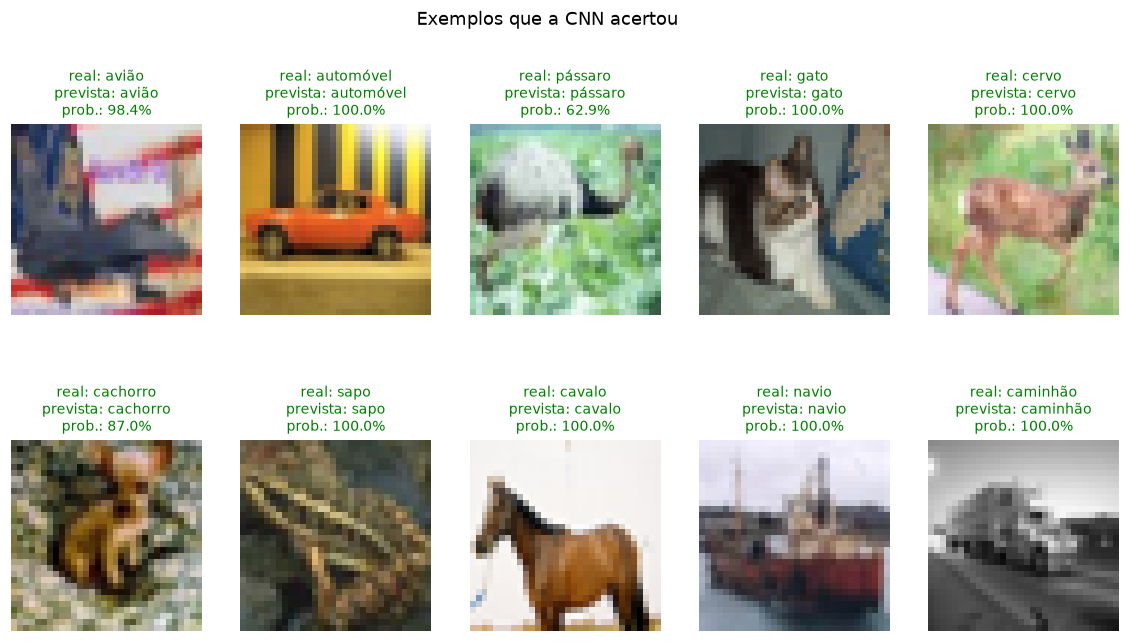

In [32]:
fixar_semente()
acertos = np.where(previstos == classes_teste)[0]
erros = np.where(previstos != classes_teste)[0]
print(f"Acertos: {len(acertos)} | Erros: {len(erros)}")

indices_certos = [int(np.random.choice(acertos[classes_teste[acertos] == c])) for c in range(10)]
grade_de_previsoes(indices_certos, imagens_teste, classes_teste, previstos, probabilidades,
                   "Exemplos que a CNN acertou", arquivo="4c_certos.png")

O que observar:
- Em 7 das 10 imagens a rede tem praticamente 100% de certeza. São imagens "típicas": o objeto aparece inteiro, centralizado e com bom contraste com o fundo.
- O avião foi acertado com 98,4%, mesmo com um fundo cheio de faixas coloridas.
- O cachorro foi acertado com 87,0%: ele é pequeno e está em cima de um fundo cheio de manchas.
- O pássaro foi acertado com só 62,9%: é um avestruz, de formato bem diferente da maioria dos pássaros da base, no meio da vegetação. Mesmo acertando, a rede ficou em dúvida.

## Exemplos classificados incorretamente
Sorteamos 10 imagens que a rede errou.

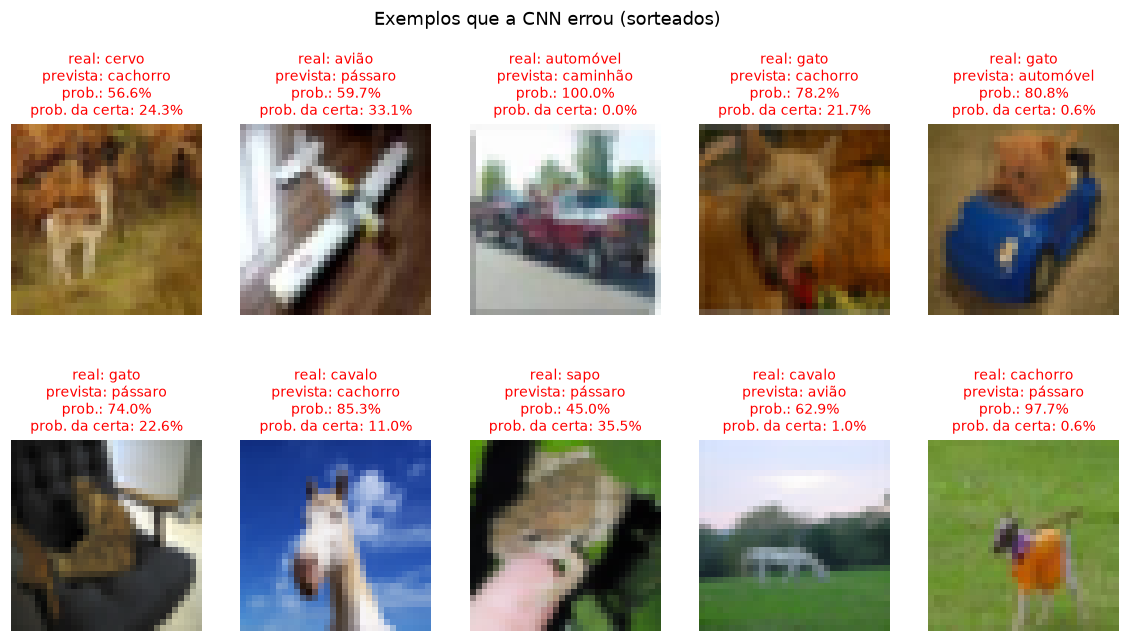

In [33]:
indices_errados = np.random.choice(erros, 10, replace=False)
grade_de_previsoes(indices_errados, imagens_teste, classes_teste, previstos, probabilidades,
                   "Exemplos que a CNN errou (sorteados)", arquivo="4c_errados.png")

O que observar:
- O gato aparece em 3 dos 10 erros (virou cachorro, automóvel e pássaro), o que combina com gato ser a classe mais difícil.
- Em metade dos erros a rede estava em dúvida: a probabilidade da classe prevista fica abaixo de 75% e a classe certa aparece como segunda opção, com 20% a 35% (cervo, avião, o gato que virou pássaro e o sapo).
- Alguns erros vêm do fundo e do tamanho do objeto: o cavalo pequeno e distante, com muito céu, virou avião, e o cachorro pequeno na grama virou pássaro.
- Em dois casos a imagem ou o rótulo é que parece duvidoso: o "automóvel" classificado como caminhão com 100% é uma picape, e o "gato" classificado como cachorro (4ª imagem) parece mesmo um cachorro.
- O gato que virou automóvel aparece junto de um carrinho azul, que ocupa a maior parte da imagem.

## Os erros mais "confiantes"
Agora as 10 imagens em que a rede errou dando a maior probabilidade para a classe errada.

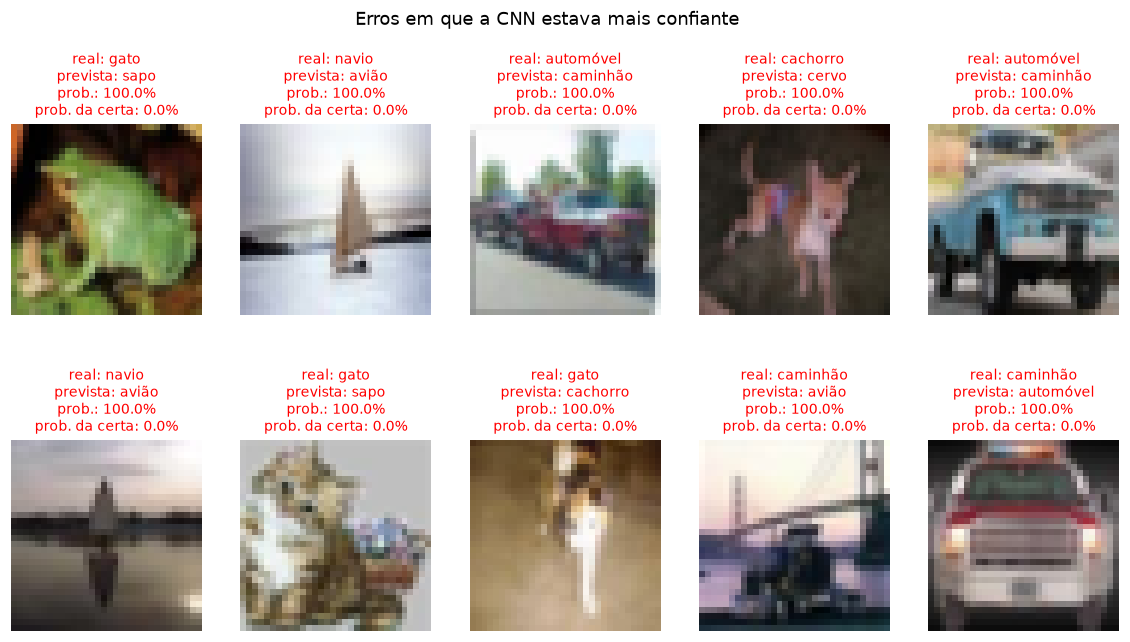

In [34]:
confianca = probabilidades.max(axis=1)
indices_confiantes = erros[np.argsort(confianca[erros])[::-1][:10]]
grade_de_previsoes(indices_confiantes, imagens_teste, classes_teste, previstos, probabilidades,
                   "Erros em que a CNN estava mais confiante", arquivo="4c_erros_confiantes.png")

O que observar:
- Nesses 10 erros a rede deu praticamente toda a probabilidade para a classe errada (100,0% depois do arredondamento para uma casa decimal) e praticamente zero para a classe certa.
- Alguns parecem erros de rótulo ou imagens ambíguas: o 1º "gato" é bem parecido com um sapo verde, e três dos veículos são picapes ou utilitários, que ficam na fronteira entre automóvel e caminhão.
- Outros mostram que a rede usa o fundo como pista: os dois navios classificados como avião são silhuetas pequenas com muito céu claro em volta.
- O cachorro magro e de pernas longas, em fundo escuro, virou cervo.
- Isso mostra uma limitação: a probabilidade da rede não é uma medida perfeita de certeza. Ela pode estar "certa de que está certa" e mesmo assim errar.

## Confiança da rede nos acertos e nos erros

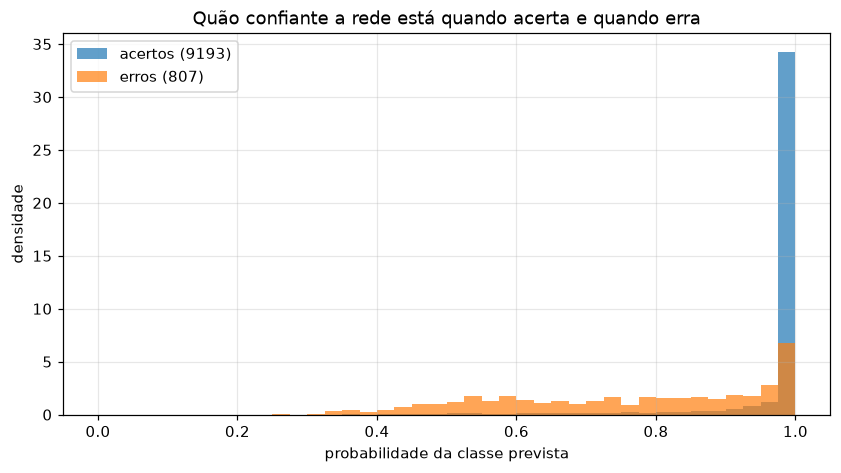

In [35]:
plt.figure(figsize=(9, 4.5))
plt.hist(confianca[acertos], bins=40, range=(0, 1), alpha=0.7, density=True, label=f"acertos ({len(acertos)})")
plt.hist(confianca[erros], bins=40, range=(0, 1), alpha=0.7, density=True, label=f"erros ({len(erros)})")
plt.xlabel("probabilidade da classe prevista")
plt.ylabel("densidade")
plt.title("Quão confiante a rede está quando acerta e quando erra")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(PASTA_FIGURAS / "4c_confianca.png", bbox_inches="tight")
plt.show()

O que observar:
- Quase todos os acertos (azul) estão encostados em 100% de probabilidade.
- Os erros (laranja) se espalham entre 30% e 100%. A maioria tem probabilidade bem menor que os acertos.
- Mas existe um grupo de erros perto de 100%: são os erros "confiantes" que vimos acima.

In [36]:
pd.DataFrame({
    "confiança média": [confianca[acertos].mean(), confianca[erros].mean()],
    "confiança mediana": [np.median(confianca[acertos]), np.median(confianca[erros])],
    "% com confiança acima de 90%": [(confianca[acertos] > 0.9).mean(), (confianca[erros] > 0.9).mean()],
}, index=["acertos", "erros"]).round(3)

,confiança média,confiança mediana,% com confiança acima de 90%
acertos,0.973,1.000,0.921
erros,0.762,0.787,0.330


Nos acertos, a confiança média é 97,3% e 92,1% deles têm mais de 90% de probabilidade. Nos erros, a confiança média cai para 76,2% e só 33,0% passam de 90%.

Então a probabilidade ajuda a separar acertos de erros: quando a rede está em dúvida, a chance de erro é bem maior. Mas não é perfeito, já que cerca de um terço dos erros ainda vem com mais de 90% de certeza.

## A probabilidade pode ser levada ao pé da letra?
Se a rede fosse bem calibrada, entre as imagens em que ela diz ter 80% de certeza ela acertaria cerca de 80%. Para conferir, separamos as imagens de teste por faixa de confiança e comparamos a confiança média de cada faixa com a acurácia real.

In [37]:
faixas = pd.cut(confianca, bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0])
tabela_calibracao = pd.DataFrame({"confiança": confianca, "acertou": previstos == classes_teste}).groupby(faixas, observed=True).agg(
    imagens=("acertou", "size"), confianca_media=("confiança", "mean"), acuracia=("acertou", "mean"))
tabela_calibracao.columns = ["imagens", "confiança média", "acurácia"]
tabela_calibracao.index.name = "faixa de confiança"
tabela_calibracao["diferença"] = tabela_calibracao["confiança média"] - tabela_calibracao["acurácia"]
erro_calibracao = (tabela_calibracao["imagens"] * tabela_calibracao["diferença"].abs()).sum() / len(confianca)
print(f"Confiança média: {confianca.mean():.3f} | acurácia: {(previstos == classes_teste).mean():.3f} | "
      f"erro de calibração (média das diferenças, pesada pelo número de imagens): {erro_calibracao:.3f}")
tabela_calibracao.round(3)

Confiança média: 0.956 | acurácia: 0.919 | erro de calibração (média das diferenças, pesada pelo número de imagens): 0.037


,imagens,confiança média,acurácia,diferença
faixa de confiança,,,,
"(0.0, 0.5]",131,0.435,0.359,0.076
"(0.5, 0.6]",216,0.550,0.435,0.114
"(0.6, 0.7]",233,0.651,0.579,0.072
"(0.7, 0.8]",287,0.751,0.610,0.141
"(0.8, 0.9]",404,0.854,0.691,0.164
"(0.9, 0.95]",384,0.927,0.807,0.120
"(0.95, 0.99]",836,0.976,0.867,0.109
"(0.99, 1.0]",7509,0.999,0.989,0.010


O que observar:
- Em todas as faixas a confiança é maior que a acurácia. A rede é confiante demais de forma sistemática, não só em alguns casos.
- A diferença é maior nas faixas do meio: quando a rede diz ter entre 80% e 90% de certeza (85% em média), ela acerta só 69%. Entre 95% e 99% (97,6% em média), acerta 86,7%.
- A faixa mais alta, acima de 99%, tem três quartos das imagens (7509) e é a mais bem calibrada: confiança de 99,9% e acurácia de 98,9%. Ainda assim, isso significa cerca de 80 erros cometidos com mais de 99% de certeza.
- No total, a confiança média é 95,6% e a acurácia é 91,9%. O erro de calibração é de 0,037, ou seja, em média a probabilidade exagera em quase 4 pontos percentuais.

Uma explicação provável, que não testamos aqui: no treino a rede acerta 99,3% das imagens, e a função de erro continua premiando probabilidades cada vez mais perto de 100% mesmo depois de acertar. A rede aprende a responder sempre com muita certeza e leva isso para as imagens novas. Existe uma correção simples para isso (dividir as saídas por uma "temperatura" ajustada na validação antes do softmax), que não muda os acertos, só deixa as probabilidades mais honestas.

---
# Conclusão

Item a
- Os filtros da primeira camada respondem a coisas simples: bordas (claro de um lado e escuro do outro), contrastes entre cores opostas e manchas de uma cor só.
- Comparando com os pesos de antes do treino, vimos que esses filtros não foram criados do zero: no final eles ainda são parecidos com os sorteados (semelhança de cosseno média de 0,85). Eles quase não mudam até a época 5, e a maior parte do ajuste acontece depois, quando a taxa de aprendizado do OneCycle está alta.

Item b
- Na camada intermediária, os mapas respondem a traços, cantos e pedaços de contorno, e o fundo liso quase não ativa.
- Ativação não é o mesmo que importância: uma rede sem treino já mostra ativação em cima dos objetos. O que o treino muda é que os mapas ficam mais seletivos e concentrados.
- Para saber quais regiões pesam na decisão usamos um teste de oclusão. As regiões importantes ficam quase sempre no próprio objeto (corpo do cavalo, rosto do gato, faixa do avião, casco do navio), e não coincidem com as regiões de maior ativação.

Item c
- A CNN acerta 9193 das 10000 imagens de teste (91,9%), quase sempre com probabilidade perto de 100%.
- Os erros acontecem em imagens difíceis (objeto pequeno, cortado ou de formato incomum), entre classes parecidas (gato e cachorro, caminhão e automóvel) e quando o fundo engana (navio com muito céu, cavalo distante).
- A rede é mais confiante quando acerta (97% em média) do que quando erra (76%). Mesmo assim, cerca de um terço dos erros vem com mais de 90% de certeza, e a confiança fica acima da acurácia em todas as faixas: a probabilidade da rede serve para ordenar as previsões, mas não deve ser lida ao pé da letra.